In [10]:
!pip install matplotlib
!pip install numpy
!pip install seaborn

In [11]:
import pandas as  pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: /Users/helinozgekar/.cache/kagglehub/datasets/asaniczka/uk-optimal-product-price-prediction/versions/3


### Part 1: Understanding Product Categories

In [3]:
df  = pd.read_csv("amz_uk_price_prediction_dataset.csv")
print(df.head())

   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  


In [4]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [5]:
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [6]:
top5_category = df['category'].value_counts()[:5]
top5_category

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

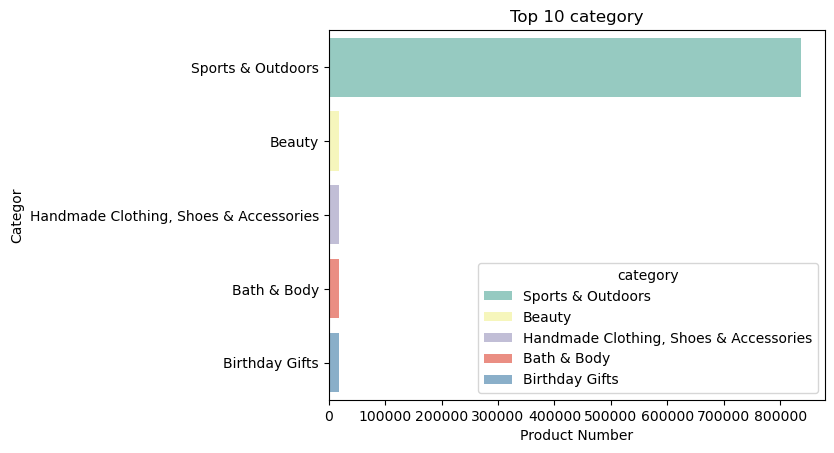

In [12]:
frequency_table = df['category'].value_counts().head(5)

ax = sns.barplot(
    y=frequency_table.index,
    x=frequency_table.values,
    palette="Set3",
    hue=frequency_table.index,
    legend=True
)

sns.move_legend(ax, "lower right")
plt.title("Top 10 category")
plt.xlabel("Product Number")
plt.ylabel("Categor")
plt.show()

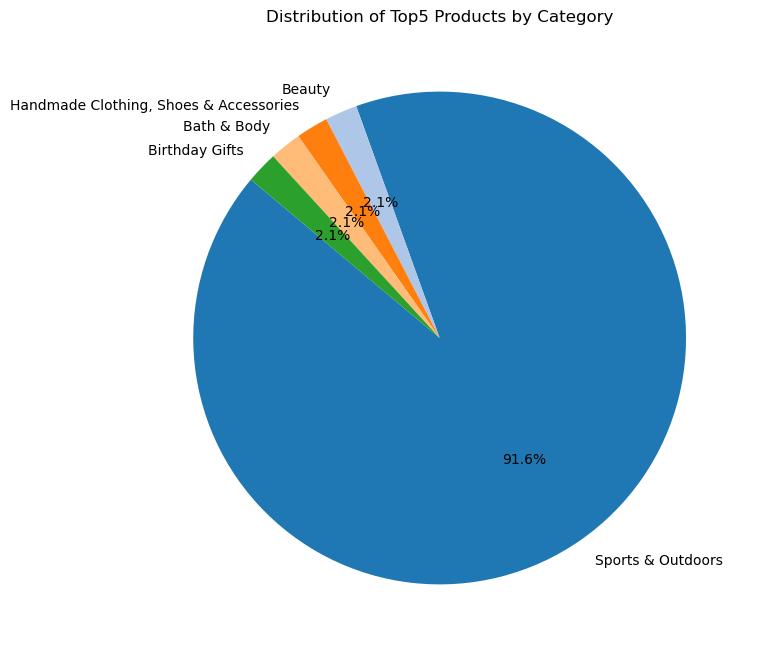

In [14]:
plt.figure(figsize=(8,8))
plt.pie(
    top5_category,
    labels=top5_category.index,
    autopct='%1.1f%%',    
    startangle=140,       
    colors=plt.cm.tab20.colors  
)
plt.title("Distribution of Top5 Products by Category")
plt.show()

### Part 2: Delving into Product Pricing

In [17]:
# Mean
mean_price = df['price'].mean()
# Median
median_price = df['price'].median()
# Mode
mode_price = df['price'].mode() 
#average
average_price = df['price'].mean()

print(f"Average Price: {average_price}")
print(f"Mean Price: {mean_price}")
print(f"Median Price: {median_price}")
print(f"Mode Price(s): {list(mode_price)}")

Average Price: 89.24380943923663
Mean Price: 89.24380943923663
Median Price: 19.09
Mode Price(s): [9.99]


In [18]:
#Variance
variance_price = df['price'].var()  

# Standard Deviation
std_dev_price = df['price'].std()  

# Range
range_price = df['price'].max() - df['price'].min()

# Interquartile Range (IQR)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
iqr_price = Q3 - Q1

print(f"Variance: {variance_price}")
print(f"Standard Deviation: {std_dev_price}")
print(f"Range: {range_price}")
print(f"Interquartile Range (IQR): {iqr_price}")

Variance: 119445.48532256528
Standard Deviation: 345.60886175352226
Range: 100000.0
Interquartile Range (IQR): 36.0


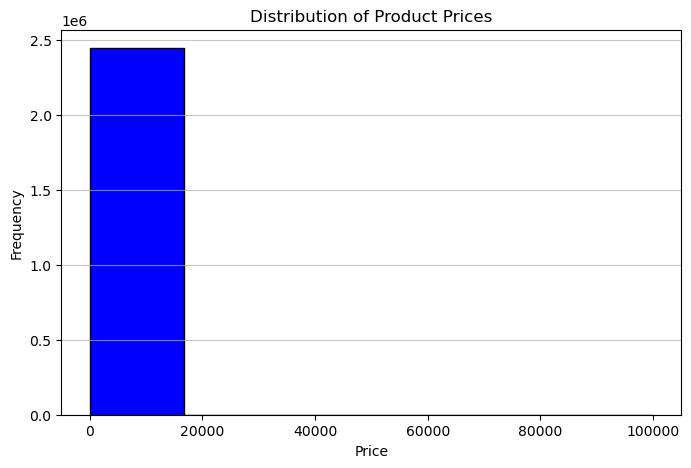

In [21]:
plt.figure(figsize=(8,5))
plt.hist(df['price'], bins=6, color='blue', edgecolor='black')
plt.title('Distribution of Product Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.7)
plt.show()

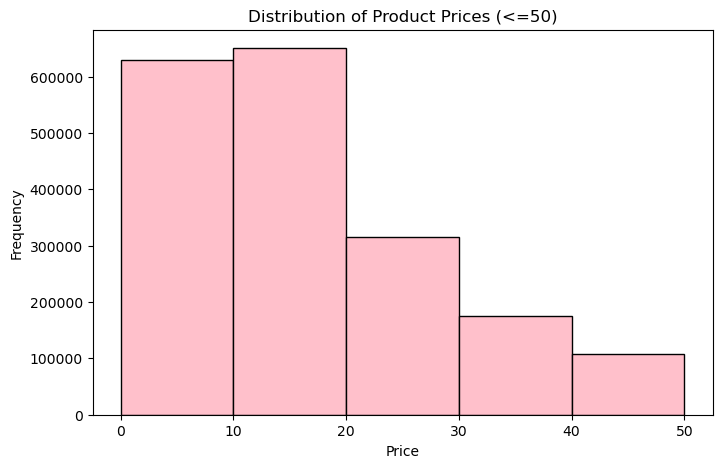

In [22]:
plt.figure(figsize=(8,5))
plt.hist(df[df['price']<=50]['price'], bins=5, color='pink', edgecolor='black')
plt.title('Distribution of Product Prices (<=50)')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

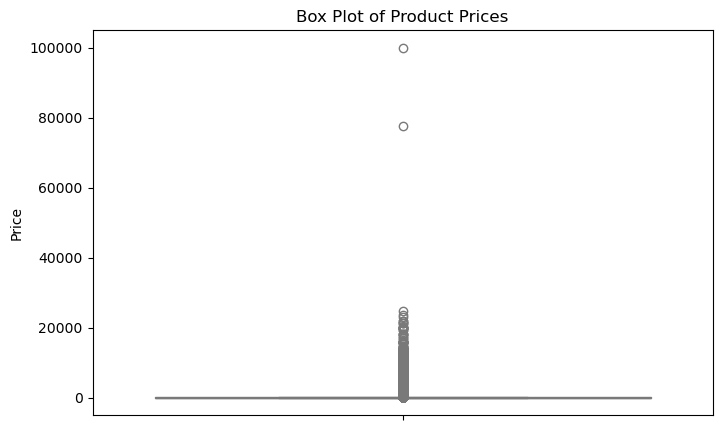

In [23]:
plt.figure(figsize=(8,5))
sns.boxplot(y=df['price'], color='lightblue')
plt.title('Box Plot of Product Prices')
plt.ylabel('Price')
plt.show()

### Part 3: Unpacking Product Ratings

In [24]:
# Mean
mean_rating = df['stars'].mean()
# Median
median_rating = df['stars'].median()
# Mode
mode_rating = df['stars'].mode() 

print(f"Mean Rating: {mean_rating}")
print(f"Median Rating: {median_rating}")
print(f"Mode Rating(s): {list(mode_rating)}")

Mean Rating: 2.152836472966065
Median Rating: 0.0
Mode Rating(s): [0.0]


In [25]:
# Variance
variance_rating = df['stars'].var()
# Standard Deviation
std_dev_rating = df['stars'].std()
# Interquartile Range (IQR)
Q1 = df['stars'].quantile(0.25)
Q3 = df['stars'].quantile(0.75)
iqr_rating = Q3 - Q1

print(f"Variance: {variance_rating}")
print(f"Standard Deviation: {std_dev_rating}")
print(f"Interquartile Range (IQR): {iqr_rating}")

Variance: 4.81743402976196
Standard Deviation: 2.1948653785054697
Interquartile Range (IQR): 4.4


In [26]:
from scipy.stats import skew, kurtosis

In [27]:
# Skewness
skewness_rating = skew(df['stars'])
# Kurtosis
kurtosis_rating = kurtosis(df['stars'])
print(f"Skewness: {skewness_rating}")
print(f"Kurtosis: {kurtosis_rating}")

Skewness: 0.08120730776283354
Kurtosis: -1.926004642549839


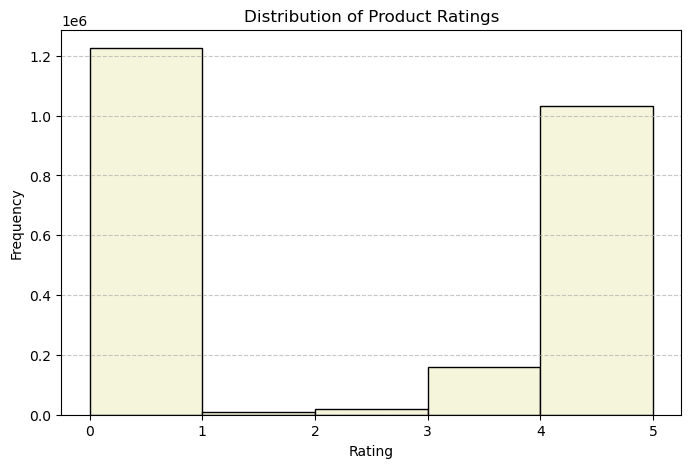

In [28]:
plt.figure(figsize=(8,5))
plt.hist(df['stars'], bins=5, color='beige', edgecolor='black')
plt.title('Distribution of Product Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()